In [1]:

print("Legal Evidence Integrity Tracker")
print("Python environment is ready!")

import pandas as pd
import hashlib
import sqlite3

print("Pandas version:", pd.__version__)
print("SHA-256 and SQL tools are available!")


Legal Evidence Integrity Tracker
Python environment is ready!
Pandas version: 2.2.3
SHA-256 and SQL tools are available!


In [2]:

import pandas as pd

# STEP 2: Generate fictional legal evidence metadata

records = []

document_types = [
    "Contract", "Email", "Deposition",
    "Invoice", "Medical Record"
]

for i in range(1, 21):
    records.append({
        "evidence_id": f"EV-{i:03d}",
        "case_id": f"CV-2026-{100 + (i % 4)}",
        "document_type": document_types[(i - 1) % 5],
        "file_name": f"evidence_{i:03d}.pdf",
        "received_date": "2026-10-25",
        "file_size_kb": 100 + (i * 15)
    })

# Introduce intentional data-quality issues
records[2]["case_id"] = "cv-2026-102"
records[5]["document_type"] = " contract "
records[8]["received_date"] = None
records[11]["file_size_kb"] = None
records[15]["case_id"] = "CV 2026 103"

# Create an exact duplicate metadata record
records[19] = records[0].copy()

# Convert to a Pandas DataFrame
df_raw = pd.DataFrame(records)

# Save the original data
df_raw.to_csv("raw_legal_evidence.csv", index=False)

print("Raw legal evidence dataset created!")
print("Total records:", len(df_raw))

display(df_raw)


Raw legal evidence dataset created!
Total records: 20


,evidence_id,case_id,document_type,file_name,received_date,file_size_kb
0,EV-001,CV-2026-101,Contract,evidence_001.pdf,2026-10-25,115.0
1,EV-002,CV-2026-102,Email,evidence_002.pdf,2026-10-25,130.0
2,EV-003,cv-2026-102,Deposition,evidence_003.pdf,2026-10-25,145.0
3,EV-004,CV-2026-100,Invoice,evidence_004.pdf,2026-10-25,160.0
4,EV-005,CV-2026-101,Medical Record,evidence_005.pdf,2026-10-25,175.0
5,EV-006,CV-2026-102,contract,evidence_006.pdf,2026-10-25,190.0
6,EV-007,CV-2026-103,Email,evidence_007.pdf,2026-10-25,205.0
7,EV-008,CV-2026-100,Deposition,evidence_008.pdf,2026-10-25,220.0
8,EV-009,CV-2026-101,Invoice,evidence_009.pdf,None,235.0
9,EV-010,CV-2026-102,Medical Record,evidence_010.pdf,2026-10-25,250.0


In [3]:

# STEP 3: Check our raw data for problems

print("DATA QUALITY REPORT")
print("-------------------")

print("Total records:", len(df_raw))

print("Duplicate records:",
      df_raw.duplicated().sum())

print("Missing values:")
print(df_raw.isnull().sum())


DATA QUALITY REPORT
-------------------
Total records: 20
Duplicate records: 1
Missing values:
evidence_id      0
case_id          0
document_type    0
file_name        0
received_date    1
file_size_kb     1
dtype: int64


In [4]:

# STEP 4: Clean legal evidence metadata

# Keep our original data unchanged
df_clean = df_raw.copy()

# Standardize case numbers
df_clean["case_id"] = (
    df_clean["case_id"]
    .str.strip()
    .str.upper()
    .str.replace(" ", "-", regex=False)
)

# Standardize document types
df_clean["document_type"] = (
    df_clean["document_type"]
    .str.strip()
    .str.title()
)

# Remove exact duplicate metadata rows
df_clean = df_clean.drop_duplicates().copy()

# Flag records with missing information
df_clean["needs_review"] = (
    df_clean["received_date"].isna()
    | df_clean["file_size_kb"].isna()
)

# Save the cleaned working dataset
df_clean.to_csv(
    "clean_legal_evidence.csv",
    index=False
)

print("DATA CLEANING COMPLETE")
print("----------------------")
print("Original records:", len(df_raw))
print("Cleaned records:", len(df_clean))
print("Duplicates removed:",
      len(df_raw) - len(df_clean))
print("Records needing review:",
      df_clean["needs_review"].sum())

display(df_clean)


DATA CLEANING COMPLETE
----------------------
Original records: 20
Cleaned records: 19
Duplicates removed: 1
Records needing review: 2


,evidence_id,case_id,document_type,file_name,received_date,file_size_kb,needs_review
0,EV-001,CV-2026-101,Contract,evidence_001.pdf,2026-10-25,115.0,False
1,EV-002,CV-2026-102,Email,evidence_002.pdf,2026-10-25,130.0,False
2,EV-003,CV-2026-102,Deposition,evidence_003.pdf,2026-10-25,145.0,False
3,EV-004,CV-2026-100,Invoice,evidence_004.pdf,2026-10-25,160.0,False
4,EV-005,CV-2026-101,Medical Record,evidence_005.pdf,2026-10-25,175.0,False
5,EV-006,CV-2026-102,Contract,evidence_006.pdf,2026-10-25,190.0,False
6,EV-007,CV-2026-103,Email,evidence_007.pdf,2026-10-25,205.0,False
7,EV-008,CV-2026-100,Deposition,evidence_008.pdf,2026-10-25,220.0,False
8,EV-009,CV-2026-101,Invoice,evidence_009.pdf,None,235.0,True
9,EV-010,CV-2026-102,Medical Record,evidence_010.pdf,2026-10-25,250.0,False


In [5]:

# STEP 5: Create sample files and calculate SHA-256 hashes

import hashlib
from pathlib import Path

# Create a folder for fictional evidence files
evidence_folder = Path("sample_evidence")
evidence_folder.mkdir(exist_ok=True)

hashes = []
actual_sizes = []

for _, row in df_clean.iterrows():

    # Create fictional document content
    content = (
        f"FICTIONAL LEGAL EVIDENCE\n"
        f"Evidence ID: {row['evidence_id']}\n"
        f"Case ID: {row['case_id']}\n"
        f"Document Type: {row['document_type']}\n"
        f"This file is for portfolio testing only.\n"
    )

    # Save as a real text file
    file_path = evidence_folder / (
        row["evidence_id"] + ".txt"
    )
    file_path.write_text(content, encoding="utf-8")

    # Calculate the SHA-256 fingerprint
    file_bytes = file_path.read_bytes()
    file_hash = hashlib.sha256(file_bytes).hexdigest()

    hashes.append(file_hash)
    actual_sizes.append(len(file_bytes))

# Add new columns to our cleaned dataset
df_clean["sha256_hash"] = hashes
df_clean["sample_file_size_bytes"] = actual_sizes

# Save updated metadata
df_clean.to_csv(
    "evidence_with_hashes.csv",
    index=False
)

print("SHA-256 HASHING COMPLETE")
print("-----------------------")
print("Files created:", len(hashes))
print("Hashes generated:", len(hashes))

display(
    df_clean[
        ["evidence_id", "case_id", "sha256_hash"]
    ].head()
)


SHA-256 HASHING COMPLETE
-----------------------
Files created: 19
Hashes generated: 19


,evidence_id,case_id,sha256_hash
0,EV-001,CV-2026-101,a69c6f5ce5abf49bffd29429fed78e74bba98897eba708...
1,EV-002,CV-2026-102,5b616153a7acd17749948991b03c863fe913dc2833a4d6...
2,EV-003,CV-2026-102,c621698c779ec86be8d4563d88d3b7c48904b08c414f9b...
3,EV-004,CV-2026-100,4b0d50d413a01b741c370cd52564691fbdccc6aafa0a38...
4,EV-005,CV-2026-101,d0724698eb350923f4fe52c5b01e063b7456efb240f66a...


In [6]:

# STEP 6: Test evidence integrity

from pathlib import Path
import hashlib

# Select one fictional evidence file
file_path = Path("sample_evidence/EV-001.txt")

# Retrieve its original fingerprint
original_hash = df_clean.loc[
    df_clean["evidence_id"] == "EV-001",
    "sha256_hash"
].iloc[0]

# Modify the file for testing
with open(file_path, "a", encoding="utf-8") as file:
    file.write("\nTEST MODIFICATION: Evidence changed.")

# Calculate its new fingerprint
new_hash = hashlib.sha256(
    file_path.read_bytes()
).hexdigest()

print("EVIDENCE INTEGRITY CHECK")
print("------------------------")
print("Evidence ID: EV-001")
print("Original hash:", original_hash)
print("Current hash: ", new_hash)

if original_hash == new_hash:
    print("RESULT: VERIFIED - File unchanged")
else:
    print("RESULT: ALERT - File has changed!")


EVIDENCE INTEGRITY CHECK
------------------------
Evidence ID: EV-001
Original hash: a69c6f5ce5abf49bffd29429fed78e74bba98897eba708e07833153a3af5c795
Current hash:  e944ed2f791dadd869ab6128c5c100f267fb0221a12a710d04c0817159ae2c0b
RESULT: ALERT - File has changed!


In [7]:

# STEP 7: Create an evidence verification log

import hashlib
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

verification_results = []

# Check every evidence record
for _, row in df_clean.iterrows():

    file_path = Path("sample_evidence") / (
        row["evidence_id"] + ".txt"
    )

    original_hash = row["sha256_hash"]

    if file_path.exists():
        current_hash = hashlib.sha256(
            file_path.read_bytes()
        ).hexdigest()

        status = (
            "VERIFIED"
            if current_hash == original_hash
            else "HASH MISMATCH"
        )
    else:
        current_hash = None
        status = "FILE MISSING"

    verification_results.append({
        "evidence_id": row["evidence_id"],
        "case_id": row["case_id"],
        "original_hash": original_hash,
        "current_hash": current_hash,
        "verification_status": status,
        "checked_at": datetime.now(
            timezone.utc
        ).isoformat()
    })

# Convert results into a table
df_verification = pd.DataFrame(
    verification_results
)

# Save the verification log
df_verification.to_csv(
    "evidence_verification_log.csv",
    index=False
)

print("EVIDENCE VERIFICATION REPORT")
print("----------------------------")

print(
    df_verification["verification_status"]
    .value_counts()
)

display(
    df_verification[
        ["evidence_id", "case_id",
         "verification_status", "checked_at"]
    ]
)


EVIDENCE VERIFICATION REPORT
----------------------------
verification_status
VERIFIED         18
HASH MISMATCH     1
Name: count, dtype: int64


,evidence_id,case_id,verification_status,checked_at
0,EV-001,CV-2026-101,HASH MISMATCH,2026-10-25T18:53:20.413643+00:00
1,EV-002,CV-2026-102,VERIFIED,2026-10-25T18:53:20.424182+00:00
2,EV-003,CV-2026-102,VERIFIED,2026-10-25T18:53:20.424723+00:00
3,EV-004,CV-2026-100,VERIFIED,2026-10-25T18:53:20.425067+00:00
4,EV-005,CV-2026-101,VERIFIED,2026-10-25T18:53:20.425378+00:00
5,EV-006,CV-2026-102,VERIFIED,2026-10-25T18:53:20.425659+00:00
6,EV-007,CV-2026-103,VERIFIED,2026-10-25T18:53:20.434412+00:00
7,EV-008,CV-2026-100,VERIFIED,2026-10-25T18:53:20.434860+00:00
8,EV-009,CV-2026-101,VERIFIED,2026-10-25T18:53:20.435182+00:00
9,EV-010,CV-2026-102,VERIFIED,2026-10-25T18:53:20.435458+00:00


In [8]:

# STEP 8: Create SQL database and load our data

import sqlite3
import pandas as pd

# Connect to our database
conn = sqlite3.connect("legal_evidence.db")

# Save cleaned evidence metadata
df_clean.to_sql(
    "evidence",
    conn,
    if_exists="replace",
    index=False
)

# Save verification results
df_verification.to_sql(
    "verification_log",
    conn,
    if_exists="append",
    index=False
)

conn.commit()

print("SQL DATABASE CREATED!")
print("---------------------")

# Ask SQL how many evidence records we have
result = pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM evidence",
    conn
)

print("Evidence records stored:",
      result["total"][0])

# Ask SQL how many verification events we have
result = pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM verification_log",
    conn
)

print("Verification events stored:",
      result["total"][0])

conn.close()


SQL DATABASE CREATED!
---------------------
Evidence records stored: 19
Verification events stored: 19


In [9]:

# STEP 9: Analyze legal evidence using SQL

import sqlite3
import pandas as pd

conn = sqlite3.connect("legal_evidence.db")

# QUERY 1: Find files that failed verification
print("1. EVIDENCE INTEGRITY ALERTS")

query1 = """
SELECT evidence_id, case_id, verification_status
FROM verification_log
WHERE verification_status != 'VERIFIED'
"""

display(pd.read_sql_query(query1, conn))


# QUERY 2: Find incomplete evidence records
print("2. RECORDS NEEDING REVIEW")

query2 = """
SELECT evidence_id, case_id, document_type
FROM evidence
WHERE needs_review = 1
"""

display(pd.read_sql_query(query2, conn))


# QUERY 3: Count evidence records per case
print("3. EVIDENCE RECORDS BY CASE")

query3 = """
SELECT case_id, COUNT(*) AS total_evidence
FROM evidence
GROUP BY case_id
ORDER BY total_evidence DESC
"""

display(pd.read_sql_query(query3, conn))

conn.close()


1. EVIDENCE INTEGRITY ALERTS


,evidence_id,case_id,verification_status
0,EV-001,CV-2026-101,HASH MISMATCH


2. RECORDS NEEDING REVIEW


,evidence_id,case_id,document_type
0,EV-009,CV-2026-101,Invoice
1,EV-012,CV-2026-100,Email


3. EVIDENCE RECORDS BY CASE


,case_id,total_evidence
0,CV-2026-102,6
1,CV-2026-103,5
2,CV-2026-101,5
3,CV-2026-100,3


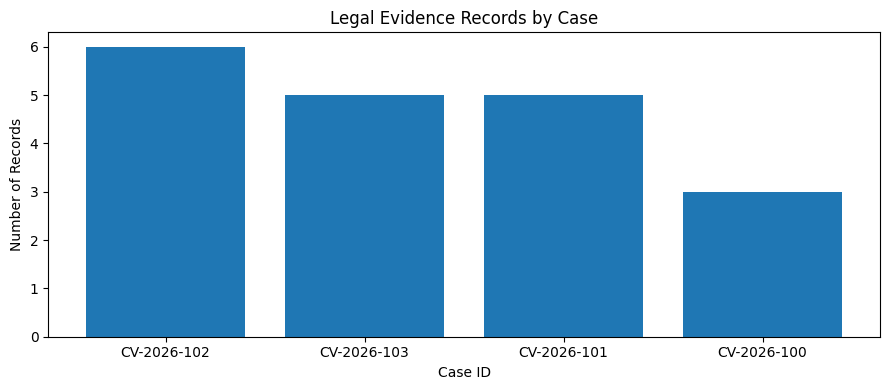

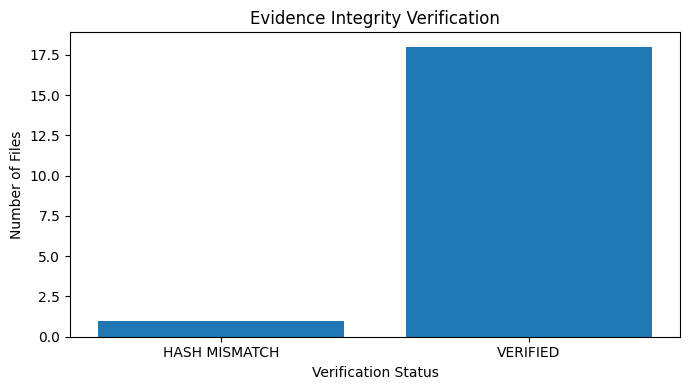

In [10]:

# STEP 10: Build our first SQL-powered dashboard

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Connect to our SQL database
conn = sqlite3.connect("legal_evidence.db")

# Retrieve case counts directly from SQL
case_data = pd.read_sql_query("""
    SELECT case_id, COUNT(*) AS total_evidence
    FROM evidence
    GROUP BY case_id
    ORDER BY total_evidence DESC
""", conn)

# Retrieve the latest verification for each file
status_data = pd.read_sql_query("""
    SELECT verification_status, COUNT(*) AS total
    FROM (
        SELECT evidence_id, verification_status,
               ROW_NUMBER() OVER (
                   PARTITION BY evidence_id
                   ORDER BY checked_at DESC, rowid DESC
               ) AS rn
        FROM verification_log
    )
    WHERE rn = 1
    GROUP BY verification_status
""", conn)

conn.close()

# Chart 1: Evidence by case
plt.figure(figsize=(9, 4))
plt.bar(
    case_data["case_id"],
    case_data["total_evidence"]
)
plt.title("Legal Evidence Records by Case")
plt.xlabel("Case ID")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Chart 2: Evidence integrity status
plt.figure(figsize=(7, 4))
plt.bar(
    status_data["verification_status"],
    status_data["total"]
)
plt.title("Evidence Integrity Verification")
plt.xlabel("Verification Status")
plt.ylabel("Number of Files")
plt.tight_layout()
plt.show()


In [11]:

# STEP 11: Back up our portfolio project

from pathlib import Path
from google.colab import files
import zipfile

backup_name = "legal_evidence_project_backup.zip"

# Include our generated files and SQL database
project_files = [
    "raw_legal_evidence.csv",
    "clean_legal_evidence.csv",
    "evidence_with_hashes.csv",
    "evidence_verification_log.csv",
    "legal_evidence.db"
]

with zipfile.ZipFile(
    backup_name, "w", zipfile.ZIP_DEFLATED
) as backup:

    for name in project_files:
        if Path(name).exists():
            backup.write(name)

    for file in Path("sample_evidence").glob("*.txt"):
        backup.write(file)

print("Project backup created!")
files.download(backup_name)


Project backup created!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

# STEP 12A: Check RapidAPI key access

from google.colab import userdata

api_key = userdata.get("RAPIDAPI_KEY")

if api_key:
    print("SUCCESS: RapidAPI key is available!")
else:
    print("ERROR: RapidAPI key was not found.")


SUCCESS: RapidAPI key is available!


In [15]:

# STEP 12C: Connect Python to RapidAPI

import requests
import json
from google.colab import userdata

# Get our saved API key
api_key = userdata.get("RAPIDAPI_KEY")

# The API address from RapidAPI
url = "https://encryptly-hashing-api.p.rapidapi.com/algorithms"

# Authentication information
headers = {
    "x-rapidapi-key": api_key,
    "x-rapidapi-host": "encryptly-hashing-api.p.rapidapi.com"
}

# Send a request to RapidAPI
try:
    response = requests.get(
        url,
        headers=headers,
        timeout=20
    )

    print("HTTP Status:", response.status_code)

    response.raise_for_status()

    # Convert the JSON response into Python data
    api_data = response.json()

    print("API CONNECTION SUCCESSFUL!")
    print("--------------------------")
    print(json.dumps(api_data, indent=2)[:4000])

except requests.exceptions.RequestException as error:
    print("API request failed:", error)

except ValueError:
    print("The response was not valid JSON.")


HTTP Status: 200
API CONNECTION SUCCESSFUL!
--------------------------
{
  "algorithms": [
    "shake_128",
    "md5",
    "shake_256",
    "sha3_224",
    "sha224",
    "sha512",
    "sha3_512",
    "sha256",
    "sha1",
    "sha384",
    "blake2s",
    "sha3_384",
    "blake2b",
    "sha3_256"
  ]
}


In [16]:

# STEP 13: Clean API data and save it to SQL

import pandas as pd
import sqlite3

# Use the API data we already retrieved
algorithms = api_data["algorithms"]

# Convert the JSON list into a Pandas table
df_algorithms = pd.DataFrame({
    "algorithm_name": algorithms
})

# Clean the names
df_algorithms["algorithm_name"] = (
    df_algorithms["algorithm_name"]
    .str.strip()
    .str.lower()
)

# Remove duplicate names if any
df_algorithms = df_algorithms.drop_duplicates()

# Identify SHA-256
df_algorithms["is_sha256"] = (
    df_algorithms["algorithm_name"] == "sha256"
)

# Connect to our existing SQL database
conn = sqlite3.connect("legal_evidence.db")

# Save API data in a new SQL table
df_algorithms.to_sql(
    "api_algorithms",
    conn,
    if_exists="replace",
    index=False
)

conn.commit()

# Verify that the data was saved
result = pd.read_sql_query("""
    SELECT *
    FROM api_algorithms
    ORDER BY algorithm_name
""", conn)

conn.close()

print("RAPIDAPI DATA CLEANED AND SAVED!")
print("--------------------------------")
print("Algorithms stored:", len(result))
print("SHA-256 available:",
      result["is_sha256"].any())

display(result)


RAPIDAPI DATA CLEANED AND SAVED!
--------------------------------
Algorithms stored: 14
SHA-256 available: True


,algorithm_name,is_sha256
0,blake2b,0
1,blake2s,0
2,md5,0
3,sha1,0
4,sha224,0
5,sha256,1
6,sha384,0
7,sha3_224,0
8,sha3_256,0
9,sha3_384,0


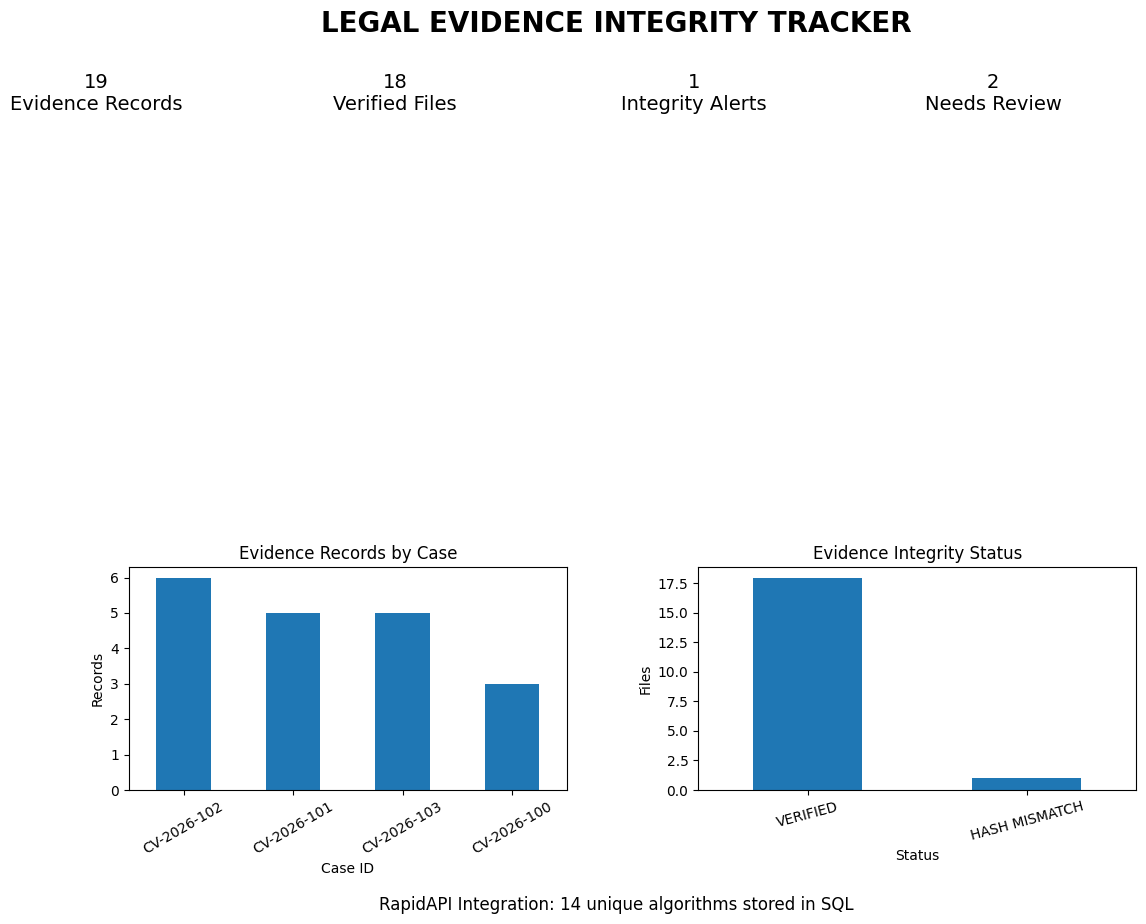

Dashboard saved successfully!


In [17]:

# STEP 14: Build our legal-tech portfolio dashboard

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("legal_evidence.db")

# Read the evidence records
evidence = pd.read_sql_query(
    "SELECT * FROM evidence", conn
)

# Read the latest verification result for each file
verification = pd.read_sql_query("""
    SELECT evidence_id, verification_status
    FROM (
        SELECT evidence_id, verification_status,
               ROW_NUMBER() OVER (
                   PARTITION BY evidence_id
                   ORDER BY checked_at DESC, rowid DESC
               ) AS rn
        FROM verification_log
    )
    WHERE rn = 1
""", conn)

# Read the API algorithm records
algorithms = pd.read_sql_query(
    "SELECT * FROM api_algorithms", conn
)

conn.close()

# Calculate dashboard metrics
total = len(evidence)
verified = (verification["verification_status"] == "VERIFIED").sum()
alerts = (verification["verification_status"] != "VERIFIED").sum()
review = evidence["needs_review"].sum()

case_counts = evidence["case_id"].value_counts()
status_counts = verification["verification_status"].value_counts()

# Create dashboard
fig = plt.figure(figsize=(13, 10))
fig.suptitle(
    "LEGAL EVIDENCE INTEGRITY TRACKER",
    fontsize=20,
    fontweight="bold"
)

# Summary metrics
metrics = [
    ("Evidence Records", total),
    ("Verified Files", verified),
    ("Integrity Alerts", alerts),
    ("Needs Review", review)
]

for i, (label, value) in enumerate(metrics):
    fig.text(
        0.10 + i * 0.23, 0.88,
        f"{value}\n{label}",
        ha="center",
        fontsize=14
    )

# Chart 1: Evidence by case
ax1 = fig.add_subplot(2, 2, 3)
case_counts.plot(kind="bar", ax=ax1)
ax1.set_title("Evidence Records by Case")
ax1.set_xlabel("Case ID")
ax1.set_ylabel("Records")
ax1.tick_params(axis="x", rotation=30)

# Chart 2: Verification status
ax2 = fig.add_subplot(2, 2, 4)
status_counts.plot(kind="bar", ax=ax2)
ax2.set_title("Evidence Integrity Status")
ax2.set_xlabel("Status")
ax2.set_ylabel("Files")
ax2.tick_params(axis="x", rotation=15)

# Chart 3: API algorithms
fig.text(
    0.5, 0.08,
    f"RapidAPI Integration: {len(algorithms)} "
    f"unique algorithms stored in SQL",
    ha="center",
    fontsize=12
)

plt.subplots_adjust(
    top=0.78,
    bottom=0.20,
    hspace=0.6,
    wspace=0.3
)

plt.savefig(
    "legal_evidence_dashboard.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved successfully!")


In [18]:

# STEP 15: Export complete project files

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

zip_name = "Legal_Evidence_Integrity_Tracker.zip"

with ZipFile(zip_name, "w", ZIP_DEFLATED) as backup:

    # Include database, datasets, and dashboard
    for name in [
        "legal_evidence.db",
        "clean_legal_evidence.csv",
        "evidence_with_hashes.csv",
        "evidence_verification_log.csv",
        "legal_evidence_dashboard.png"
    ]:
        if Path(name).exists():
            backup.write(name)

    # Include fictional evidence files
    for path in Path("sample_evidence").glob("*.txt"):
        backup.write(path)

print("Portfolio files packaged successfully!")
files.download(zip_name)


Portfolio files packaged successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

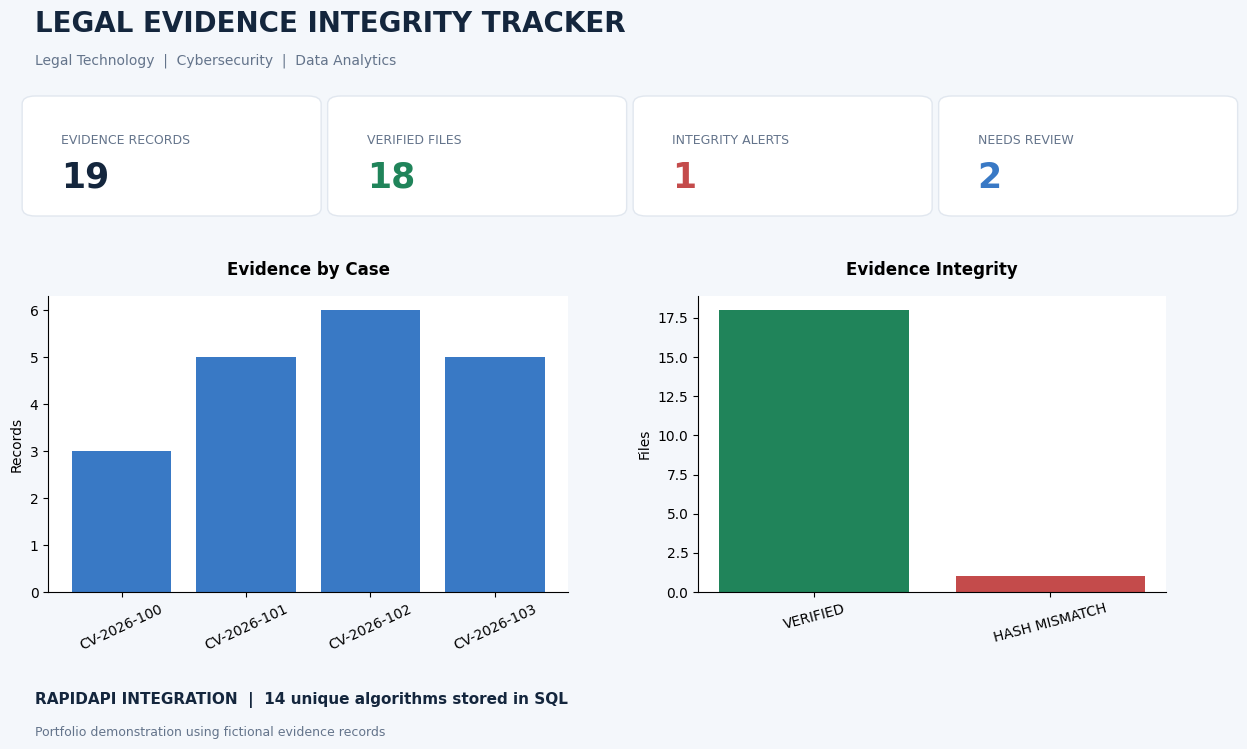

Professional dashboard saved!


In [19]:

# STEP 16: Professional legal-tech dashboard

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

conn = sqlite3.connect("legal_evidence.db")

evidence = pd.read_sql_query(
    "SELECT * FROM evidence", conn
)

verification = pd.read_sql_query("""
    SELECT evidence_id, verification_status
    FROM (
        SELECT evidence_id, verification_status,
               ROW_NUMBER() OVER (
                   PARTITION BY evidence_id
                   ORDER BY checked_at DESC, rowid DESC
               ) AS rn
        FROM verification_log
    )
    WHERE rn = 1
""", conn)

algorithms = pd.read_sql_query(
    "SELECT * FROM api_algorithms", conn
)

conn.close()

total = len(evidence)
verified = int(
    (verification["verification_status"] == "VERIFIED").sum()
)
alerts = int(
    (verification["verification_status"] != "VERIFIED").sum()
)
review = int(evidence["needs_review"].sum())

case_counts = evidence["case_id"].value_counts().sort_index()
status_counts = verification["verification_status"].value_counts()

# Dashboard styling
navy = "#14263D"
blue = "#3979C5"
green = "#20845A"
red = "#C44B4B"
gray = "#64748B"
background = "#F4F7FB"

fig = plt.figure(figsize=(13, 8), facecolor=background)

fig.text(
    0.06, 0.94, "LEGAL EVIDENCE INTEGRITY TRACKER",
    fontsize=20, fontweight="bold", color=navy
)
fig.text(
    0.06, 0.90,
    "Legal Technology  |  Cybersecurity  |  Data Analytics",
    fontsize=10, color=gray
)

metrics = [
    ("EVIDENCE RECORDS", total, navy),
    ("VERIFIED FILES", verified, green),
    ("INTEGRITY ALERTS", alerts, red),
    ("NEEDS REVIEW", review, blue)
]

for i, (label, value, color) in enumerate(metrics):
    x = 0.06 + i * 0.235

    card = FancyBboxPatch(
        (x, 0.72), 0.21, 0.13,
        boxstyle="round,pad=0.01",
        transform=fig.transFigure,
        facecolor="white",
        edgecolor="#E1E7EF"
    )
    fig.add_artist(card)

    fig.text(x + 0.02, 0.80, label,
             fontsize=9, color=gray)
    fig.text(x + 0.02, 0.745, str(value),
             fontsize=25, fontweight="bold", color=color)

# Evidence by case
ax1 = fig.add_axes([0.07, 0.24, 0.40, 0.37])
ax1.set_facecolor("white")
ax1.bar(case_counts.index, case_counts.values, color=blue)
ax1.set_title("Evidence by Case", fontweight="bold", pad=15)
ax1.set_ylabel("Records")
ax1.tick_params(axis="x", rotation=25)
ax1.spines[["top", "right"]].set_visible(False)

# Verification results
ax2 = fig.add_axes([0.57, 0.24, 0.36, 0.37])
ax2.set_facecolor("white")

status_colors = [
    green if status == "VERIFIED" else red
    for status in status_counts.index
]

ax2.bar(
    status_counts.index,
    status_counts.values,
    color=status_colors
)
ax2.set_title("Evidence Integrity", fontweight="bold", pad=15)
ax2.set_ylabel("Files")
ax2.tick_params(axis="x", rotation=15)
ax2.spines[["top", "right"]].set_visible(False)

# Footer
fig.text(
    0.06, 0.10,
    f"RAPIDAPI INTEGRATION  |  "
    f"{len(algorithms)} unique algorithms stored in SQL",
    fontsize=11, color=navy, fontweight="bold"
)
fig.text(
    0.06, 0.06,
    "Portfolio demonstration using fictional evidence records",
    fontsize=9, color=gray
)

plt.savefig(
    "legal_evidence_dashboard_final.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Professional dashboard saved!")


In [20]:

from google.colab import files

files.download("legal_evidence_dashboard_final.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>